# Parte 3 - Experimentos y Evaluacion

En este notebook se entrena el agente REINFORCE en los 6 entornos pedidos por la consigna.

Para cada uno:
- Entrenar hasta que el entorno se considere resuelto.
- Graficar la recompensa (o largo de trayectoria, segun el entorno) por trayectoria, con lineas de referencia de un agente aleatorio y de agentes triviales (accion constante)
- Graficar la loss por trayectoria.
- Para CartPole y Acrobot, ademas grabar un video de una trayectoria evaluada de forma deterministica.

## Setup

Se importan las piezas construidas en las Partes 1 y 2:

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import gymnasium as gym
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

from envs import TwoAZeroObsOneStep, TwoARandomObsOneStep, LineWorldEasyEnv, LineWorldMirrorEnv
from barrido import barrido, crear_entorno, apilar, SEMILLAS
from reinforce import REINFORCEAgent

GAMMA = 0.99
SEED = 0
N_ITERACIONES = 150
BATCH_SIZE = 16

# Cada experimento se corre con varias semillas y lo que se reporta es siempre el promedio
# El barrido corre las semillas en paralelo
print("semillas del barrido:", SEMILLAS)

WEIGHTS_DIR = Path("weights")
WEIGHTS_DIR.mkdir(exist_ok=True)

resultados = {}

torch.manual_seed(SEED)
np.random.seed(SEED)

print("torch:", torch.__version__)
print("gymnasium:", gym.__version__)

semillas del barrido: [0, 1, 2, 3, 4]
torch: 2.13.0+cpu
gymnasium: 1.3.0


### TensorBoard

Ademas de los graficos matplotlib, cada entrenamiento loguea a TensorBoard. Cada entorno guarda su corrida en una carpeta `runs/reinforce_<entorno>/`.

Para verlo desde una terminal:

```
tensorboard --logdir=runs
```

y abrir `http://localhost:6006`. En la Parte 4 se reusa la carpeta `runs/` para las corridas de REINFORCE con baseline (`runs/reinforce_baseline_<entorno>/`)

## Funciones auxiliares

In [ ]:
COLORES_REF = ["tab:gray", "tab:orange", "tab:purple", "tab:brown"]


def run_fixed_policy(env, policy_fn, n_episodes=200, max_steps=1000, seed=0):
    """Corre n_episodes con una politica fija (no entrena)

    Devuelve (retorno promedio, largo promedio, fraccion de trayectorias que
    terminaron por 'terminated=True')

    max_steps es un corte de seguridad, aparte del limite de
    cada entorno: si un agente trivial que toma siempre la
    accion "mala" en LineWorldMirrorEnv por ejemplo nunca llegaria al
    objetivo y la trayectoria correria para siempre si no se lo corta 
    explicitamente
    """
    ep_returns, ep_lengths, ep_terminated = [], [], []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        terminated = truncated = False
        total_reward, steps = 0.0, 0
        while not (terminated or truncated) and steps < max_steps:
            action = policy_fn(obs)
            obs, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            steps += 1
        ep_returns.append(total_reward)
        ep_lengths.append(steps)
        ep_terminated.append(terminated)
    return float(np.mean(ep_returns)), float(np.mean(ep_lengths)), float(np.mean(ep_terminated))


def random_baseline(env, n_episodes=200, max_steps=1000, seed=0):
    avg_return, avg_length, _ = run_fixed_policy(env, lambda obs: env.action_space.sample(),
                                                   n_episodes, max_steps, seed)
    return avg_return, avg_length


def trivial_baselines(env, n_episodes=200, max_steps=1000, seed=0):
    """Retorno y largo promedio por cada accion constante, solo para las que
    llegan al estado terminal la mayoria de las veces (no por timeout)"""
    results = {}
    for a in range(env.action_space.n):
        avg_return, avg_length, frac_terminated = run_fixed_policy(env, lambda obs, a=a: a,
                                                                     n_episodes, max_steps, seed)
        if frac_terminated > 0.5:
            results[a] = (avg_return, avg_length)
    return results


def moving_average(x, window):
    x = np.asarray(x, dtype=float)
    if len(x) < window:
        return x
    kernel = np.ones(window) / window
    return np.convolve(x, kernel, mode="valid")


def curvas_del_barrido(resultados_semillas, clave, smooth_window=10):
    """Devuelve (x, una curva cruda por semilla, x del promedio, promedio suavizado)"""
    matriz = apilar(resultados_semillas, clave)
    x = np.arange(matriz.shape[1])
    x_suave = np.arange(smooth_window - 1, matriz.shape[1])
    return x, matriz, x_suave, moving_average(matriz.mean(axis=0), smooth_window)


def plot_barrido(resultados_semillas, env_name, y_key="episode_return", y_label="Retorno",
                 reference_lines=None, smooth_window=10, loss_key="loss"):
    """Dos paneles: la metrica de desempeno y la loss. En cada uno van las
    semillas sin suavizar en fino y el promedio suavizado en grueso"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, clave, color, etiqueta in [(axes[0], y_key, "tab:blue", y_label),
                                       (axes[1], loss_key, "tab:red", "Loss")]:
        x, por_semilla, x_suave, promedio = curvas_del_barrido(resultados_semillas, clave, smooth_window)
        for k, fila in enumerate(por_semilla):
            ax.plot(x, fila, color=color, alpha=0.3, linewidth=0.8,
                    label=f"{len(por_semilla)} semillas" if k == 0 else None)
        ax.plot(x_suave, promedio, color=color, linewidth=2,
                label="promedio suavizado")
        ax.set_xlabel("Trayectoria")
        ax.set_ylabel(etiqueta)
        ax.grid(True, alpha=0.3)

    if reference_lines:
        for (etiqueta, y), color in zip(reference_lines.items(), COLORES_REF):
            axes[0].axhline(y, linestyle="--", linewidth=1, color=color, label=etiqueta)

    axes[0].set_title(f"{env_name} - {y_label.lower()}")
    axes[1].set_title(f"{env_name} - loss")
    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def registrar_en_tensorboard(nombre_run, resultados_semillas, y_key, loss_key="loss"):
    """Manda a TensorBoard la curva promedio del barrido, que es lo que se
    reporta en el resto del trabajo"""
    metrica = apilar(resultados_semillas, y_key).mean(axis=0)
    perdida = apilar(resultados_semillas, loss_key).mean(axis=0)
    etiqueta = "EpisodeReturn" if y_key == "episode_return" else "EpisodeLength"
    writer = SummaryWriter(log_dir=f"runs/{nombre_run}")
    for t, (v, l) in enumerate(zip(metrica, perdida)):
        writer.add_scalar(f"Performance/{etiqueta}", v, t)
        writer.add_scalar("Loss/train", l, t)
    writer.close()


def agente_de_referencia(env, resultados_semillas, lr=1e-2):
    """Reconstruye el agente de la semilla de referencia (la primera del
    barrido) a partir de sus pesos. Se usa para inspeccionar la politica, para
    grabar los videos y para guardar los pesos entregados: cosas que
    necesitan una politica concreta y no un promedio"""
    agente = REINFORCEAgent(env.observation_space, env.action_space, lr=lr)
    agente.policy.load_state_dict(resultados_semillas[0]["pesos"])
    return agente


## 1. TwoAZeroObsOneStep

Caso mas simple: un solo paso, observacion siempre 0, accion 1 da +1 y accion 0 da -1. No hay estado, sirve para verificar que REINFORCE puede aumentar la probabilidad de la acción de mayor recompensa cuando no hay ninguna información de estado de por medio

Con un solo paso por trayectoria y sin descuento relevante, resuelto significa: la politica converge a elegir siempre la accion 1 y el retorno promedio tiende a +1

agente aleatorio: retorno promedio = 0.110
agentes triviales (accion -> retorno): {0: -1.0, 1: 1.0}


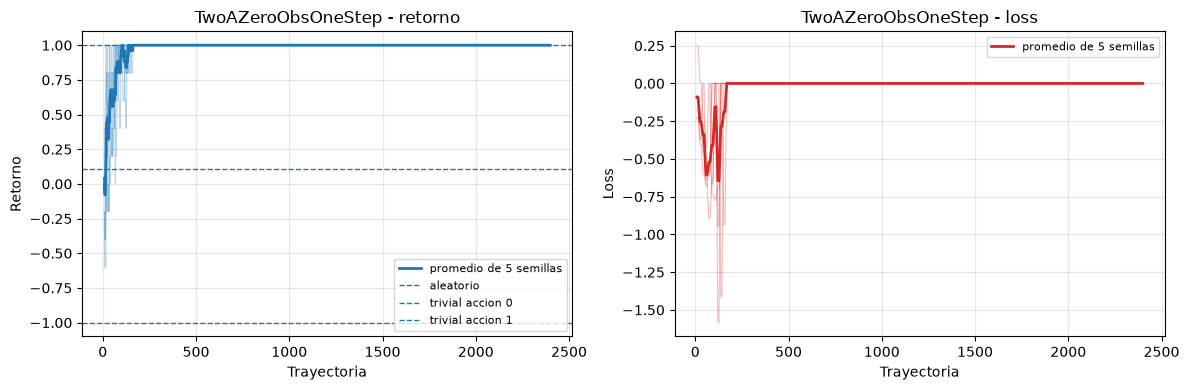

In [ ]:
# El entorno de referencia se crea con semilla fija asi la linea del agente aleatorio no se mueve entre corridas 
env = crear_entorno("TwoAZeroObsOneStep", semilla=0)

rand_ret, _ = random_baseline(env)
trivial_ret = trivial_baselines(env)
trivial_summary = {a: ret for a, (ret, _) in trivial_ret.items()}
print(f"agente aleatorio: retorno promedio = {rand_ret:.3f}")
print(f"agentes triviales (accion -> retorno): {trivial_summary}")

res_two_a_zero = barrido("TwoAZeroObsOneStep", n_iterations=N_ITERACIONES,
                         batch_size=BATCH_SIZE, gamma=GAMMA, policy_lr=1e-2)
registrar_en_tensorboard("reinforce_TwoAZeroObsOneStep", res_two_a_zero, "episode_return")

agent_two_a_zero = agente_de_referencia(env, res_two_a_zero)
agent_two_a_zero.save(WEIGHTS_DIR / "reinforce_TwoAZeroObsOneStep.pt")

reference_lines = {"aleatorio": rand_ret}
for a, (ret, _) in trivial_ret.items():
    reference_lines[f"trivial accion {a}"] = ret

resultados["TwoAZeroObsOneStep"] = dict(semillas=res_two_a_zero, refs=reference_lines,
                                        y_key="episode_return", y_label="Retorno")

plot_barrido(res_two_a_zero, "TwoAZeroObsOneStep", reference_lines=reference_lines)

La loss no mide un error contra una respuesta correcta como en
supervisado, es el negativo del objetivo de REINFORCE para que
Adam (que minimiza) termine haciendo gradiente ascendente sobre el retorno esperado. 

No
aplica la idea de "loss mas baja = mejor politica", y por eso la curva de la derecha en cada
grafico sube, baja y no se asienta. Para saber si el agente aprende hay que mirar la de la
izquierda. 

Igual se le agrega media movil, para poder ver la tendencia de fondo pese al ruido.

## 2. TwoARandomObsOneStep

Igual de un paso, pero ahora la observacion (S1 o S2, al azar) determina cual accion es buena (no aprende una preferencia fija). Demuestra que la red usa la observacion: ninguna accion constante puede dar mas de 0 de retorno promedio (por eso el baseline trivial deberia rondar 0), asi que si la politica converge a +1 es porque aprendio a condicionar la accion en el estado.

agente aleatorio: retorno promedio = -0.060
agentes triviales (accion -> retorno): {0: 0.11, 1: -0.11}


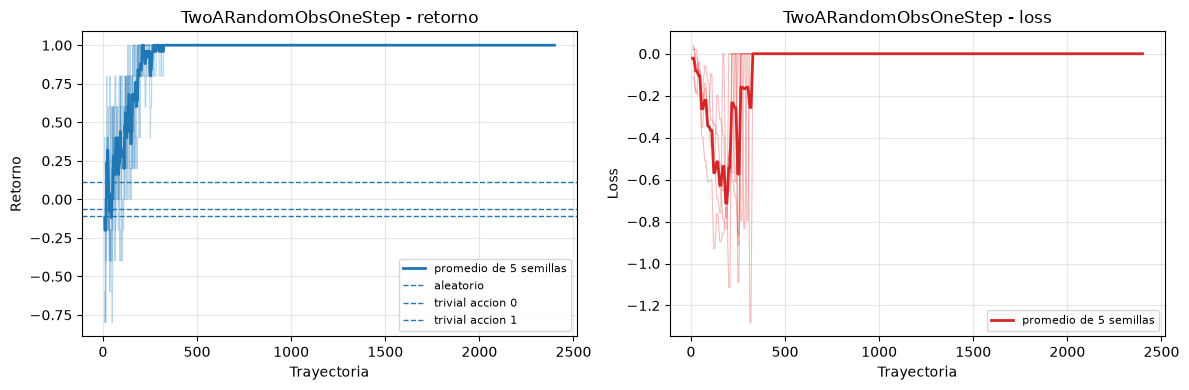

In [5]:
env = crear_entorno("TwoARandomObsOneStep", semilla=0)

rand_ret, _ = random_baseline(env)
trivial_ret = trivial_baselines(env)
trivial_summary = {a: ret for a, (ret, _) in trivial_ret.items()}
print(f"agente aleatorio: retorno promedio = {rand_ret:.3f}")
print(f"agentes triviales (accion -> retorno): {trivial_summary}")

res_two_a_random = barrido("TwoARandomObsOneStep", n_iterations=N_ITERACIONES,
                           batch_size=BATCH_SIZE, gamma=GAMMA, policy_lr=1e-2)
registrar_en_tensorboard("reinforce_TwoARandomObsOneStep", res_two_a_random, "episode_return")

agent_two_a_random = agente_de_referencia(env, res_two_a_random)
agent_two_a_random.save(WEIGHTS_DIR / "reinforce_TwoARandomObsOneStep.pt")

reference_lines = {"aleatorio": rand_ret}
for a, (ret, _) in trivial_ret.items():
    reference_lines[f"trivial accion {a}"] = ret

resultados["TwoARandomObsOneStep"] = dict(semillas=res_two_a_random, refs=reference_lines,
                                          y_key="episode_return", y_label="Retorno")

plot_barrido(res_two_a_random, "TwoARandomObsOneStep", reference_lines=reference_lines)

## 3. LineWorldEasyEnv

Pasillo de 6 casilleros, +1 solo al llegar al extremo derecho, 0 en el resto, y sin limite de pasos. El retorno total termina siendo 1 casi siempre (hasta un agente aleatorio llega tarde o temprano) asi que la metrica que realmente muestra aprendizaje es el largo de la trayectoria: cuantos pasos tarda en llegar. El optimo es 5 (ir siempre a la derecha).

Por eso se grafica `episode_length` en vez de `episode_return`.

agente aleatorio: largo promedio de trayectoria = 31.1 pasos
agentes triviales que llegan a la meta (accion -> pasos): {1: 5.0}


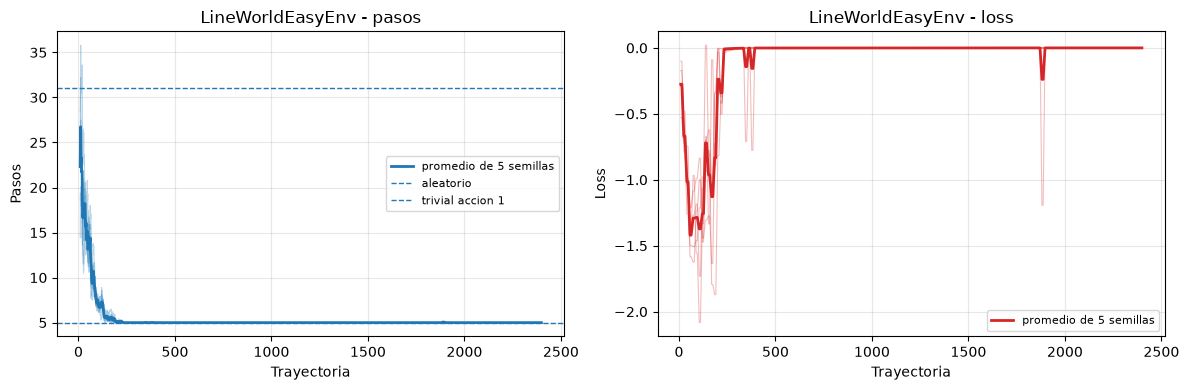

In [7]:
env = crear_entorno("LineWorldEasyEnv", semilla=0)

rand_ret, rand_len = random_baseline(env)
trivial_ret = trivial_baselines(env)
print(f"agente aleatorio: largo promedio de trayectoria = {rand_len:.1f} pasos")
print("agentes triviales que llegan a la meta (accion -> pasos):",
      {a: length for a, (_, length) in trivial_ret.items()})

res_line_easy = barrido("LineWorldEasyEnv", n_iterations=N_ITERACIONES,
                        batch_size=BATCH_SIZE, gamma=GAMMA, policy_lr=1e-2)
registrar_en_tensorboard("reinforce_LineWorldEasyEnv", res_line_easy, "episode_length")

agent_line_easy = agente_de_referencia(env, res_line_easy)
agent_line_easy.save(WEIGHTS_DIR / "reinforce_LineWorldEasyEnv.pt")

reference_lines = {"aleatorio": rand_len}
for a, (_, length) in trivial_ret.items():
    reference_lines[f"trivial accion {a}"] = length

resultados["LineWorldEasyEnv"] = dict(semillas=res_line_easy, refs=reference_lines,
                                      y_key="episode_length", y_label="Pasos")

plot_barrido(res_line_easy, "LineWorldEasyEnv", y_key="episode_length", y_label="Pasos",
             reference_lines=reference_lines)

## 4. LineWorldMirrorEnv

Pasillo de 4 estados donde en la posicion 2 las acciones estan invertidas. Recompensa -1 por paso, asi que menos pasos = mejor. Ninguna accion constante resuelve esto, es la prueba de que la politica condiciona en el estado a lo largo de varios pasos, no solo en un bandit de un paso. El optimo es 3 pasos (derecha, izquierda, derecha)

agente aleatorio: largo promedio de trayectoria = 11.7 pasos
agentes triviales que llegan a la meta (accion -> pasos): {}


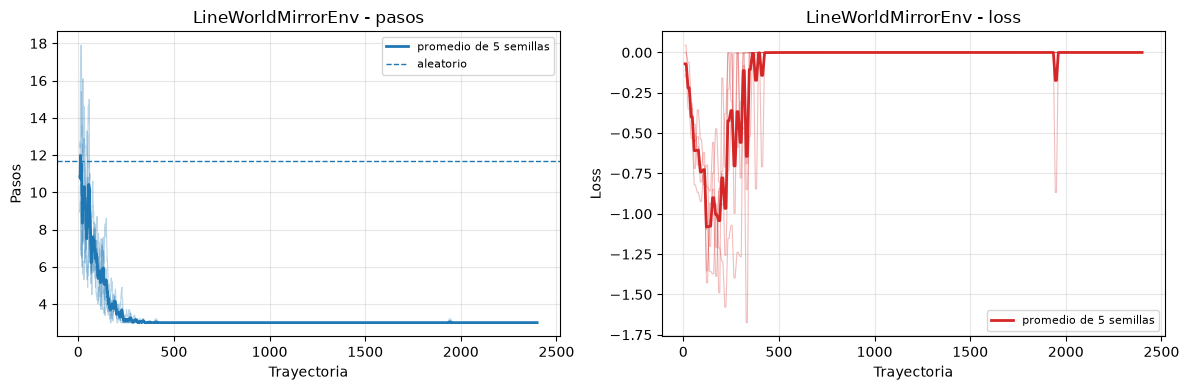

In [8]:
env = crear_entorno("LineWorldMirrorEnv", semilla=0)

rand_ret, rand_len = random_baseline(env)
trivial_ret = trivial_baselines(env)
print(f"agente aleatorio: largo promedio de trayectoria = {rand_len:.1f} pasos")
print("agentes triviales que llegan a la meta (accion -> pasos):",
      {a: length for a, (_, length) in trivial_ret.items()})

res_line_mirror = barrido("LineWorldMirrorEnv", n_iterations=N_ITERACIONES,
                          batch_size=BATCH_SIZE, gamma=GAMMA, policy_lr=1e-2)
registrar_en_tensorboard("reinforce_LineWorldMirrorEnv", res_line_mirror, "episode_length")

agent_line_mirror = agente_de_referencia(env, res_line_mirror)
agent_line_mirror.save(WEIGHTS_DIR / "reinforce_LineWorldMirrorEnv.pt")

reference_lines = {"aleatorio": rand_len}
for a, (_, length) in trivial_ret.items():
    reference_lines[f"trivial accion {a}"] = length

resultados["LineWorldMirrorEnv"] = dict(semillas=res_line_mirror, refs=reference_lines,
                                        y_key="episode_length", y_label="Pasos")

plot_barrido(res_line_mirror, "LineWorldMirrorEnv", y_key="episode_length", y_label="Pasos",
             reference_lines=reference_lines)

## 5. CartPole-v1

CartPole tiene observacion continua (posicion y velocidad del carro, angulo y velocidad angular del palo - 4 numeros), 2 acciones (empujar el carro a izquierda o derecha), recompensa +1 por cada paso que el palo se mantiene en pie, y la trayectoria corta a los 500 pasos (limite propio del entorno). Se considera resuelto con un retorno promedio cercano a 500.

A diferencia de los otros env, aca la observacion es un `Box` (vector continuo), no un `Discrete`.

Antes de entrenar se prueba un grid search chico de learning rate

In [ ]:
# Cada candidato tambien se corre con las cinco semillas y se compara por el promedio
grid_lrs = [1e-2, 5e-3, 1e-3]
n_probe_iters = 15
probe_batch_size = 16

grid_scores = {}
for lr in grid_lrs:
    probe = barrido("CartPole-v1", n_iterations=n_probe_iters, batch_size=probe_batch_size,
                    gamma=GAMMA, policy_lr=lr)
    ultimas = apilar(probe, "episode_return")[:, -5 * probe_batch_size:]
    grid_scores[lr] = float(ultimas.mean())
    print(f"lr={lr}: retorno = {grid_scores[lr]:.1f} "
          f"+-{ultimas.mean(axis=1).std():.1f}")

best_lr_cartpole = max(grid_scores, key=grid_scores.get)
print(f"-> se elige lr={best_lr_cartpole}")

lr=0.01: retorno = 73.8 +-8.7


lr=0.005: retorno = 47.1 +-2.6


lr=0.001: retorno = 26.8 +-2.6
-> se elige lr=0.01


agente aleatorio: retorno promedio = 25.1
agentes triviales (accion -> retorno): {0: 9.4, 1: 9.18}


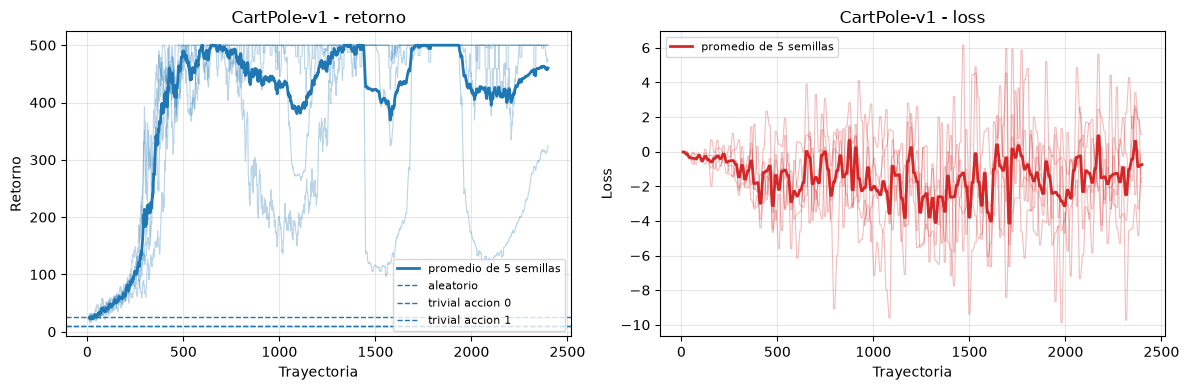

In [10]:
env = crear_entorno("CartPole-v1", semilla=0)

rand_ret, _ = random_baseline(env, n_episodes=50)
trivial_ret = trivial_baselines(env, n_episodes=50)
trivial_summary = {a: ret for a, (ret, _) in trivial_ret.items()}
print(f"agente aleatorio: retorno promedio = {rand_ret:.1f}")
print(f"agentes triviales (accion -> retorno): {trivial_summary}")

res_cartpole = barrido("CartPole-v1", n_iterations=N_ITERACIONES,
                       batch_size=BATCH_SIZE, gamma=GAMMA, policy_lr=best_lr_cartpole)
registrar_en_tensorboard("reinforce_CartPole-v1", res_cartpole, "episode_return")

agent_cartpole = agente_de_referencia(env, res_cartpole, lr=best_lr_cartpole)
agent_cartpole.save(WEIGHTS_DIR / "reinforce_CartPole-v1.pt")

reference_lines = {"aleatorio": rand_ret}
for a, (ret, _) in trivial_ret.items():
    reference_lines[f"trivial accion {a}"] = ret

resultados["CartPole-v1"] = dict(semillas=res_cartpole, refs=reference_lines,
                                 y_key="episode_return", y_label="Retorno")

plot_barrido(res_cartpole, "CartPole-v1", reference_lines=reference_lines)

### Video de evaluacion (CartPole-v1)

In [ ]:
from gymnasium.wrappers import RecordVideo

video_folder = "videos/cartpole"
eval_env = gym.make("CartPole-v1", render_mode="rgb_array")
# episode_trigger=lambda ep: True: se corre un solo trayectoria
eval_env = RecordVideo(eval_env, video_folder=video_folder, name_prefix="cartpole_eval",
                        episode_trigger=lambda ep: True)

obs, _ = eval_env.reset(seed=123)
terminated = truncated = False
total_reward = 0.0
while not (terminated or truncated):
    # act_deterministic, evaluar de forma deterministica
    action = agent_cartpole.act_deterministic(obs)
    obs, reward, terminated, truncated, _ = eval_env.step(action)
    total_reward += reward
eval_env.close()

print(f"video guardado en '{video_folder}/', retorno de la trayectoria evaluada: {total_reward:.0f}")

C:\xampp\htdocs\TP1-RL-PolicyGradient\.venv\Lib\site-packages\gymnasium\wrappers\rendering.py:292: UserWarning: WARN: Overwriting existing videos at C:\xampp\htdocs\TP1-RL-PolicyGradient\videos\cartpole folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


video guardado en 'videos/cartpole/', retorno de la trayectoria evaluada: 500


## 6. Acrobot-v1

Pendulo doble con 2 articulaciones. Observacion continua de 6 numeros (seno y coseno de los dos angulos, mas las dos velocidades angulares), 3 acciones (aplicar torque -1, 0 o +1 en la articulacion), recompensa -1 por paso hasta que el extremo del pendulo supera cierta altura (ahi termina la trayectoria), con corte a los 500 pasos si no lo logra. Como el retorno es -1 por paso, mas negativo = peor, un retorno cercano a -500 significa que nunca llego

In [12]:
grid_scores = {}
for lr in grid_lrs:
    probe = barrido("Acrobot-v1", n_iterations=n_probe_iters, batch_size=probe_batch_size,
                    gamma=GAMMA, policy_lr=lr)
    ultimas = apilar(probe, "episode_return")[:, -5 * probe_batch_size:]
    grid_scores[lr] = float(ultimas.mean())
    print(f"lr={lr}: retorno = {grid_scores[lr]:.1f} "
          f"+-{ultimas.mean(axis=1).std():.1f}")

best_lr_acrobot = max(grid_scores, key=grid_scores.get)
print(f"-> se elige lr={best_lr_acrobot}")

lr=0.01: retorno = -267.5 +-189.8


lr=0.005: retorno = -265.5 +-135.6


lr=0.001: retorno = -465.8 +-51.2
-> se elige lr=0.005


agente aleatorio: retorno promedio = -494.2
agentes triviales (accion -> retorno): {}


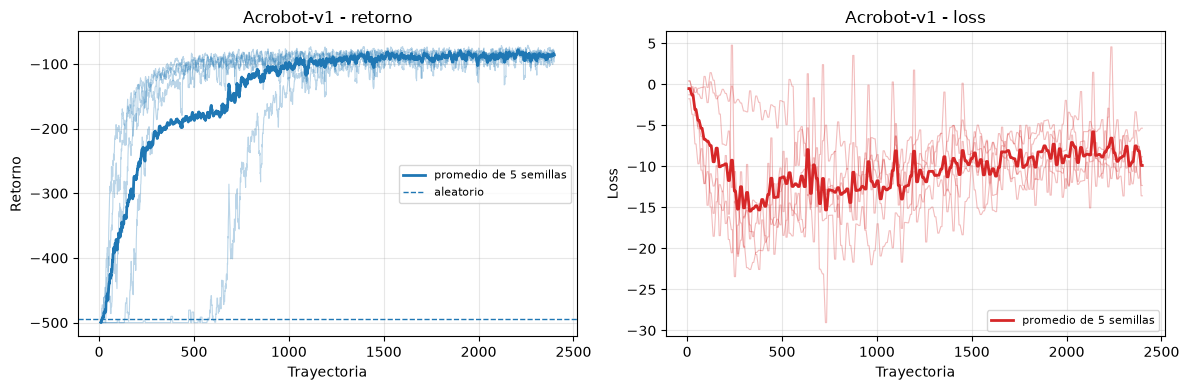

In [13]:
env = crear_entorno("Acrobot-v1", semilla=0)

rand_ret, _ = random_baseline(env, n_episodes=50)
trivial_ret = trivial_baselines(env, n_episodes=50)
trivial_summary = {a: ret for a, (ret, _) in trivial_ret.items()}
print(f"agente aleatorio: retorno promedio = {rand_ret:.1f}")
print(f"agentes triviales (accion -> retorno): {trivial_summary}")

res_acrobot = barrido("Acrobot-v1", n_iterations=N_ITERACIONES,
                      batch_size=BATCH_SIZE, gamma=GAMMA, policy_lr=best_lr_acrobot)
registrar_en_tensorboard("reinforce_Acrobot-v1", res_acrobot, "episode_return")

agent_acrobot = agente_de_referencia(env, res_acrobot, lr=best_lr_acrobot)
agent_acrobot.save(WEIGHTS_DIR / "reinforce_Acrobot-v1.pt")

reference_lines = {"aleatorio": rand_ret}
for a, (ret, _) in trivial_ret.items():
    reference_lines[f"trivial accion {a}"] = ret

resultados["Acrobot-v1"] = dict(semillas=res_acrobot, refs=reference_lines,
                                y_key="episode_return", y_label="Retorno")

plot_barrido(res_acrobot, "Acrobot-v1", reference_lines=reference_lines)

### Video de evaluacion (Acrobot-v1)

In [14]:
video_folder = "videos/acrobot"
eval_env = gym.make("Acrobot-v1", render_mode="rgb_array")
eval_env = RecordVideo(eval_env, video_folder=video_folder, name_prefix="acrobot_eval",
                        episode_trigger=lambda ep: True)

obs, _ = eval_env.reset(seed=123)
terminated = truncated = False
total_reward = 0.0
while not (terminated or truncated):
    action = agent_acrobot.act_deterministic(obs)
    obs, reward, terminated, truncated, _ = eval_env.step(action)
    total_reward += reward
eval_env.close()

print(f"video guardado en '{video_folder}/', retorno de la trayectoria evaluada: {total_reward:.0f}")

C:\xampp\htdocs\TP1-RL-PolicyGradient\.venv\Lib\site-packages\gymnasium\wrappers\rendering.py:292: UserWarning: WARN: Overwriting existing videos at C:\xampp\htdocs\TP1-RL-PolicyGradient\videos\acrobot folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


video guardado en 'videos/acrobot/', retorno de la trayectoria evaluada: -79


## Figura resumen de los 6 entornos

entornos incluidos: ['TwoAZeroObsOneStep', 'TwoARandomObsOneStep', 'LineWorldEasyEnv', 'LineWorldMirrorEnv', 'CartPole-v1', 'Acrobot-v1']


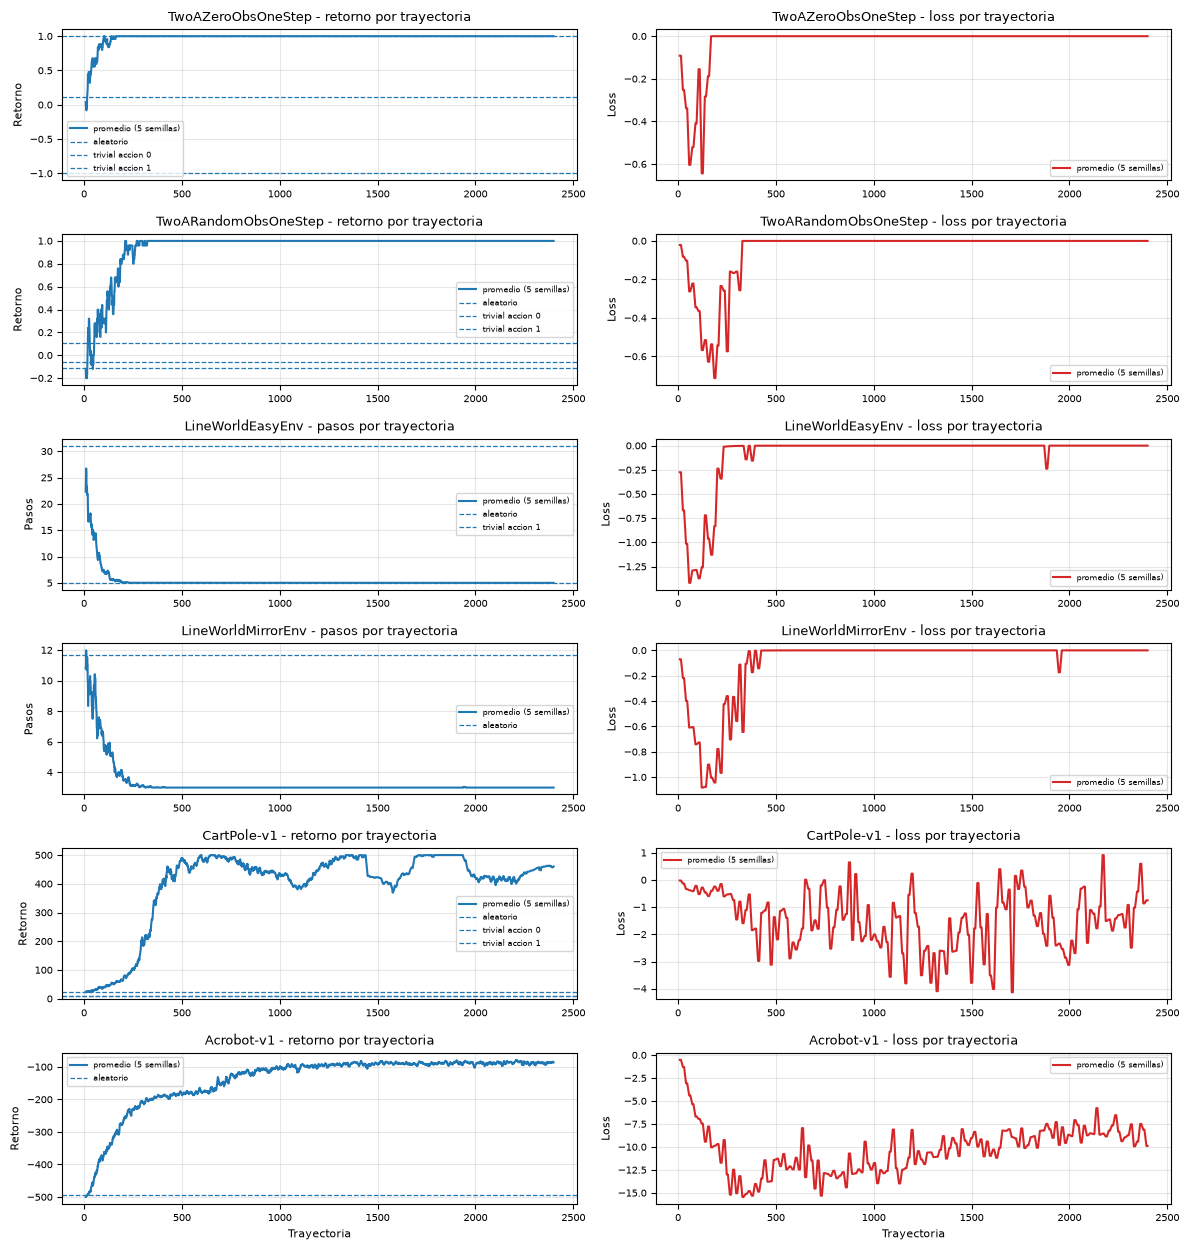

In [15]:
def plot_resumen_entornos(resultados, smooth_window=10):
    """Una sola figura con los seis entornos apilados: una fila por entorno,
    a la izquierda la metrica principal con sus lineas de referencia y a la
    derecha la loss. Las filas son bajitas a proposito para que la figura
    entera entre en una pagina del informe.

    Son los mismos graficos individuales de cada entorno, juntos: las semillas
    crudas en fino y el promedio suavizado en grueso."""
    fig, axes = plt.subplots(len(resultados), 2, figsize=(12, 2.1 * len(resultados)))

    for fila, (env_name, r) in enumerate(resultados.items()):
        x, por_semilla, x_suave, promedio = curvas_del_barrido(r["semillas"], r["y_key"], smooth_window)
        _, por_semilla_loss, _, promedio_loss = curvas_del_barrido(r["semillas"], "loss", smooth_window)

        ax = axes[fila, 0]
        for k, curva in enumerate(por_semilla):
            ax.plot(x, curva, color="tab:blue", alpha=0.3, linewidth=0.8,
                    label=f"{len(SEMILLAS)} semillas" if k == 0 else None)
        ax.plot(x_suave, promedio, color="tab:blue", linewidth=2,
                label="promedio suavizado")
        for (label, y), color in zip(r["refs"].items(), COLORES_REF):
            ax.axhline(y, linestyle="--", linewidth=0.9, color=color, label=label)
        ax.set_ylabel(r["y_label"], fontsize=8)
        ax.set_title(f"{env_name} - {r['y_label'].lower()} por trayectoria", fontsize=9)
        ax.legend(fontsize=6, loc="best")

        ax = axes[fila, 1]
        for k, curva in enumerate(por_semilla_loss):
            ax.plot(x, curva, color="tab:red", alpha=0.3, linewidth=0.8,
                    label=f"{len(SEMILLAS)} semillas" if k == 0 else None)
        ax.plot(x_suave, promedio_loss, color="tab:red", linewidth=2,
                label="promedio suavizado")
        ax.set_ylabel("Loss", fontsize=8)
        ax.set_title(f"{env_name} - loss por trayectoria", fontsize=9)
        ax.legend(fontsize=6, loc="best")

        for ax in axes[fila]:
            ax.tick_params(labelsize=7)
            ax.grid(True, alpha=0.3)

    # el eje x solo se etiqueta en la ultima fila, para no repetirlo seis veces
    for ax in axes[-1]:
        ax.set_xlabel("Trayectoria", fontsize=8)

    fig.tight_layout()
    plt.show()


print("entornos incluidos:", list(resultados))
plot_resumen_entornos(resultados)

# Parte 4 - REINFORCE con Baseline

Para reducir la varianza, en vez de mover la politica con R(t), se la mueve con la ventaja A(t) = R(t) - V(s_t), donde V(s_t) es una estimacion de cuanto retorno se espera desde este estado.

(sigue siendo un estimador no sesgado, es la misma cuenta que ya se vio con la normalizacion de retornos en la Parte 2)

V(s) se aprende con una segunda red (value.py), entrenada por regresion para predecir R(t) a partir de s_t. El algoritmo esta en `reinforce_baseline.py`: la parte de politica es la misma, solo se le agrega la red de valor y se cambia R(t) por A(t) en el update

In [ ]:
from reinforce_baseline import REINFORCEBaselineAgent


def agente_baseline_de_referencia(env, resultados_semillas, policy_lr, value_lr):
    """Igual que agente_de_referencia pero para el agente con baseline: hay que
    recuperar las dos redes, la de politica y la de valor"""
    agente = REINFORCEBaselineAgent(env.observation_space, env.action_space,
                                    policy_lr=policy_lr, value_lr=value_lr)
    agente.policy.load_state_dict(resultados_semillas[0]["pesos"]["policy"])
    agente.value_net.load_state_dict(resultados_semillas[0]["pesos"]["value"])
    return agente


def plot_baseline_comparison(res_sin_baseline, res_con_baseline, env_name, smooth_window=10):
    """Superpone, para el mismo entorno, la curva de retorno y la de loss de
    politica sin baseline (Parte 3) contra con baseline (Parte 4)"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    corridas = [(res_sin_baseline, "sin baseline", "tab:blue", "loss"),
                (res_con_baseline, "con baseline", "tab:green", "policy_loss")]

    for resultados_semillas, etiqueta, color, _ in corridas:
        x, por_semilla, x_suave, promedio = curvas_del_barrido(resultados_semillas, "episode_return", smooth_window)
        for fila in por_semilla:
            axes[0].plot(x, fila, color=color, alpha=0.25, linewidth=0.7)
        axes[0].plot(x_suave, promedio, color=color, linewidth=2, label=etiqueta)
    axes[0].set_xlabel("Trayectoria")
    axes[0].set_ylabel("Retorno (media movil)")
    axes[0].set_title(f"{env_name} - retorno")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    for resultados_semillas, etiqueta, color, clave_loss in corridas:
        x, por_semilla, x_suave, promedio = curvas_del_barrido(resultados_semillas, clave_loss, smooth_window)
        for fila in por_semilla:
            axes[1].plot(x, fila, color=color, alpha=0.25, linewidth=0.7)
        axes[1].plot(x_suave, promedio, color=color, linewidth=2, label=etiqueta)
    axes[1].set_xlabel("Trayectoria")
    axes[1].set_ylabel("Loss de politica (media movil)")
    axes[1].set_title(f"{env_name} - loss de politica")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()


def dispersion_entre_semillas(resultados_semillas, clave="episode_return", ultimas=480):
    """Desvio tipico entre semillas en el tramo final del entrenamiento. Es la
    medida directa de lo que el baseline deberia mejorar."""
    matriz = apilar(resultados_semillas, clave)[:, -ultimas:]
    return float(matriz.mean(axis=1).std())


def plot_diagnostico_baseline(resultados_semillas, env_name, smooth_window=10):
    """Izquierda: si la red de valor ajusta. Derecha: cuanta dispersion le saca
    el baseline al estimador, comparando R(t) contra A(t) sobre el mismo batch"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    _, _, x_suave, promedio = curvas_del_barrido(resultados_semillas, "value_loss", smooth_window)
    axes[0].plot(x_suave, promedio, color="tab:purple")
    axes[0].set_ylabel("Loss de la red de valor")
    axes[0].set_title(f"{env_name} - ajuste de V(s)")

    for clave, color, etiqueta in [("return_std", "tab:blue", "R(t)"),
                                   ("advantage_std", "tab:green", "A(t) = R(t) - V(s)")]:
        _, _, x_suave, promedio = curvas_del_barrido(resultados_semillas, clave, smooth_window)
        axes[1].plot(x_suave, promedio, color=color, label=etiqueta)
    axes[1].set_ylabel("Desvio dentro del batch")
    axes[1].set_title(f"{env_name} - dispersion del estimador")
    axes[1].legend()

    for ax in axes:
        ax.set_xlabel("Trayectoria")
        ax.grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()

## CartPole-v1 con baseline

Mismo `n_iterations` y `batch_size` que en la Parte 3.

El `policy_lr` no se vuelve a buscar: se hereda el que eligio la Parte 3. 

El grid busca solo el `value_lr` que afecta unicamente a la red de valor y no reescala el gradiente de la politica

In [ ]:
value_lr_candidates = [1e-2, 1e-3]
best_policy_lr = best_lr_cartpole

grid_results = {}
for value_lr in value_lr_candidates:
    probe = barrido("CartPole-v1", n_iterations=n_probe_iters, batch_size=probe_batch_size,
                    gamma=GAMMA, policy_lr=best_policy_lr, con_baseline=True, value_lr=value_lr)
    retorno = apilar(probe, "episode_return")[:, -5 * probe_batch_size:]
    value_loss = apilar(probe, "value_loss")[:, -5 * probe_batch_size:]
    grid_results[value_lr] = (float(retorno.mean()), float(value_loss.mean()))
    print(f"value_lr={value_lr}: retorno={retorno.mean():.1f} "
          f"+-{retorno.mean(axis=1).std():.1f}, value_loss={value_loss.mean():.1f}")

best_value_lr = max(grid_results, key=lambda k: grid_results[k][0])
print(f"-> policy_lr={best_policy_lr} (Parte 3), value_lr={best_value_lr}")

value_lr=0.01: retorno=92.6 +-21.3, value_loss=1832.6


value_lr=0.001: retorno=100.7 +-24.1, value_loss=2071.6
-> policy_lr=0.01 (Parte 3), value_lr=0.001


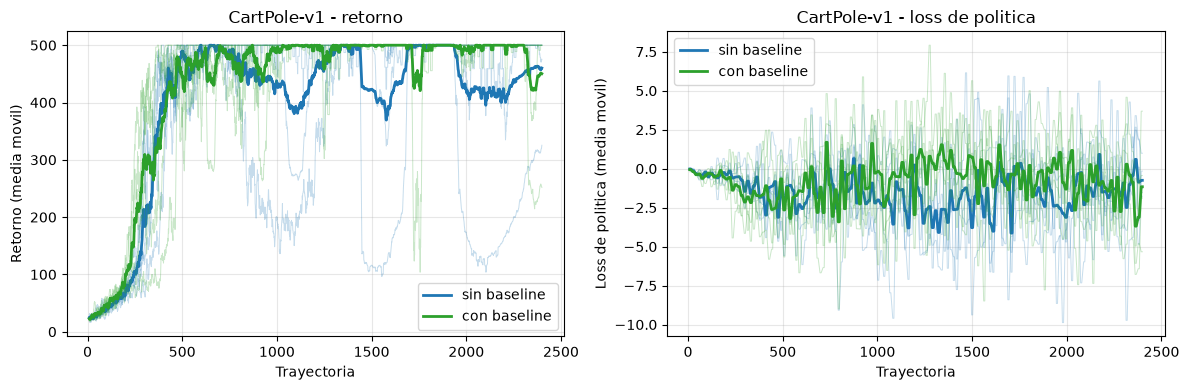

dispersion entre semillas -- sin baseline: 111.9, con baseline: 17.3


In [19]:
env = crear_entorno("CartPole-v1", semilla=0)

res_cartpole_baseline = barrido("CartPole-v1", n_iterations=N_ITERACIONES, batch_size=BATCH_SIZE,
                                gamma=GAMMA, policy_lr=best_policy_lr,
                                con_baseline=True, value_lr=best_value_lr)
registrar_en_tensorboard("reinforce_baseline_CartPole-v1", res_cartpole_baseline,
                         "episode_return", loss_key="policy_loss")

# guarda las dos redes juntas (politica y valor) de la semilla de referencia
agent_cartpole_baseline = agente_baseline_de_referencia(env, res_cartpole_baseline,
                                                        best_policy_lr, best_value_lr)
agent_cartpole_baseline.save(WEIGHTS_DIR / "reinforce_baseline_CartPole-v1.pt")
env.close()

plot_baseline_comparison(res_cartpole, res_cartpole_baseline, "CartPole-v1")

print(f"dispersion entre semillas -- sin baseline: {dispersion_entre_semillas(res_cartpole):.1f}, "
      f"con baseline: {dispersion_entre_semillas(res_cartpole_baseline):.1f}")
plot_diagnostico_baseline(res_cartpole_baseline, "CartPole-v1")

## Acrobot-v1 con baseline

Mismo criterio que en CartPole: presupuesto identico al de la Parte 3, `policy_lr` heredado
de la Parte 3, y grid solo sobre `value_lr`.

In [ ]:
value_lr_candidates = [1e-2, 1e-3]
best_policy_lr = best_lr_acrobot

grid_results = {}
for value_lr in value_lr_candidates:
    probe = barrido("Acrobot-v1", n_iterations=n_probe_iters, batch_size=probe_batch_size,
                    gamma=GAMMA, policy_lr=best_policy_lr, con_baseline=True, value_lr=value_lr)
    retorno = apilar(probe, "episode_return")[:, -5 * probe_batch_size:]
    value_loss = apilar(probe, "value_loss")[:, -5 * probe_batch_size:]
    grid_results[value_lr] = (float(retorno.mean()), float(value_loss.mean()))
    print(f"value_lr={value_lr}: retorno={retorno.mean():.1f} "
          f"+-{retorno.mean(axis=1).std():.1f}, value_loss={value_loss.mean():.1f}")

best_value_lr = max(grid_results, key=lambda k: grid_results[k][0])
print(f"-> policy_lr={best_policy_lr} (Parte 3), value_lr={best_value_lr}")

value_lr=0.01: retorno=-265.6 +-121.2, value_loss=4412.8


value_lr=0.001: retorno=-254.0 +-124.1, value_loss=4393.7
-> policy_lr=0.005 (Parte 3), value_lr=0.001


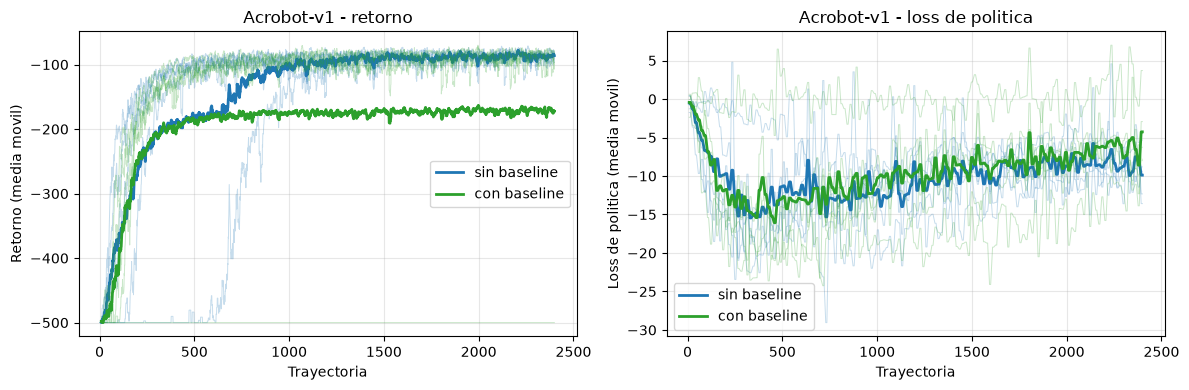

dispersion entre semillas -- sin baseline: 1.7, con baseline: 164.2


In [21]:
env = crear_entorno("Acrobot-v1", semilla=0)

res_acrobot_baseline = barrido("Acrobot-v1", n_iterations=N_ITERACIONES, batch_size=BATCH_SIZE,
                               gamma=GAMMA, policy_lr=best_policy_lr,
                               con_baseline=True, value_lr=best_value_lr)
registrar_en_tensorboard("reinforce_baseline_Acrobot-v1", res_acrobot_baseline,
                         "episode_return", loss_key="policy_loss")

agent_acrobot_baseline = agente_baseline_de_referencia(env, res_acrobot_baseline,
                                                       best_policy_lr, best_value_lr)
agent_acrobot_baseline.save(WEIGHTS_DIR / "reinforce_baseline_Acrobot-v1.pt")
env.close()

plot_baseline_comparison(res_acrobot, res_acrobot_baseline, "Acrobot-v1")

print(f"dispersion entre semillas -- sin baseline: {dispersion_entre_semillas(res_acrobot):.1f}, "
      f"con baseline: {dispersion_entre_semillas(res_acrobot_baseline):.1f}")
plot_diagnostico_baseline(res_acrobot_baseline, "Acrobot-v1")